In [ ]:
# Step 1: Import libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.svm import SVR

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [ ]:
# Step 2: Upload dataset

from google.colab import files

uploaded = files.upload()

Saving aqi.csv to aqi.csv


In [ ]:
import pandas as pd

df = pd.read_csv("aqi.csv")

df.head()


,date,state,area,number_of_monitoring_stations,prominent_pollutants,aqi_value,air_quality_status,unit,note
0,30-04-2025,Maharashtra,Amravati,2,PM10,78,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
1,30-04-2025,Bihar,Purnia,1,CO,56,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
2,30-04-2025,Madhya Pradesh,Katni,1,O3,98,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN
3,30-04-2025,Chhattisgarh,Tumidih,1,PM10,103,Moderate,number_of_monitoring_stations in Absolute Numb...,NaN
4,30-04-2025,Assam,Byrnihat,1,PM2.5,61,Satisfactory,number_of_monitoring_stations in Absolute Numb...,NaN


In [ ]:
# Display number of rows and columns

print("Dataset Shape:", df.shape)

# Display column names
print("\nColumn Names:")
print(df.columns.tolist())

# Display dataset information
df.info()

# Display statistical summary
df.describe()

Dataset Shape: (235785, 9)

Column Names:
['date', 'state', 'area', 'number_of_monitoring_stations', 'prominent_pollutants', 'aqi_value', 'air_quality_status', 'unit', 'note']
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235785 entries, 0 to 235784
Data columns (total 9 columns):
 #   Column                         Non-Null Count   Dtype  
---  ------                         --------------   -----  
 0   date                           235785 non-null  object 
 1   state                          235785 non-null  object 
 2   area                           235785 non-null  object 
 3   number_of_monitoring_stations  235785 non-null  int64  
 4   prominent_pollutants           235785 non-null  object 
 5   aqi_value                      235785 non-null  int64  
 6   air_quality_status             235785 non-null  object 
 7   unit                           235785 non-null  object 
 8   note                           0 non-null       float64
dtypes: float64(1), int64(2), object(6)
mem

,number_of_monitoring_stations,aqi_value,note
count,235785.000000,235785.000000,0.0
mean,1.870653,111.127294,NaN
std,3.071575,71.447353,NaN
min,1.000000,3.000000,NaN
25%,1.000000,59.000000,NaN
50%,1.000000,92.000000,NaN
75%,1.000000,142.000000,NaN
max,40.000000,500.000000,NaN


Missing values in each column:
date                                  0
state                                 0
area                                  0
number_of_monitoring_stations         0
prominent_pollutants                  0
aqi_value                             0
air_quality_status                    0
unit                                  0
note                             235785
dtype: int64


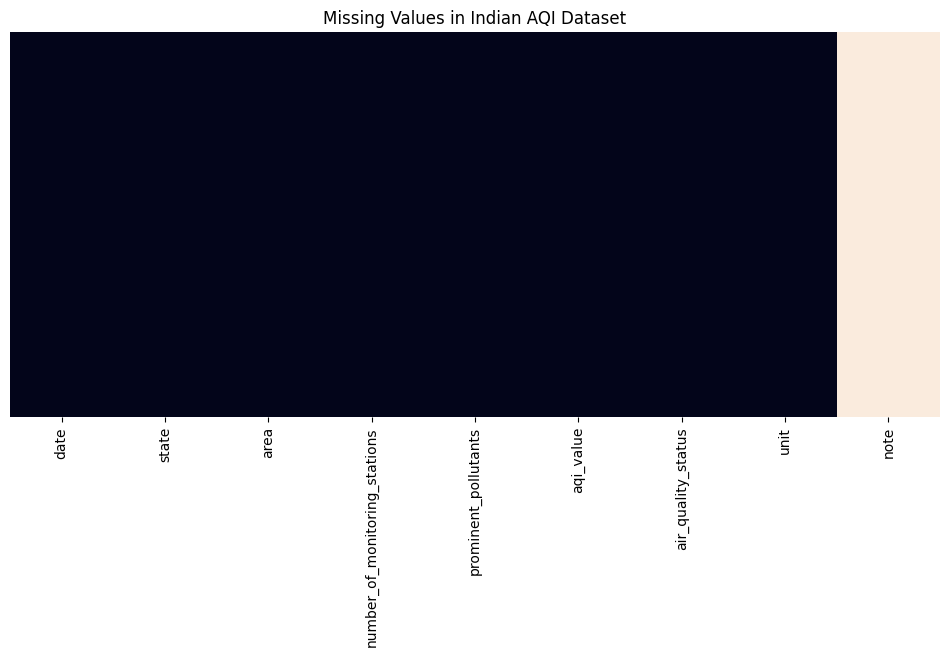

In [ ]:
# Step 4: Check missing values

missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

# Visualize missing values
plt.figure(figsize=(12, 5))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False
)

plt.title("Missing Values in Indian AQI Dataset")
plt.show()

In [ ]:
# Remove columns that contain only missing values

df = df.dropna(axis=1, how="all")

# Check missing values again

print(df.isnull().sum())

# Display updated dataset shape

print("Dataset shape:", df.shape)

date                             0
state                            0
area                             0
number_of_monitoring_stations    0
prominent_pollutants             0
aqi_value                        0
air_quality_status               0
unit                             0
dtype: int64
Dataset shape: (235785, 8)


In [ ]:
# Step 3: Check duplicate rows

print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [ ]:
# Remove duplicate records

df = df.drop_duplicates()

print("Dataset shape after removing duplicates:", df.shape)

Dataset shape after removing duplicates: (235785, 8)


In [ ]:
# Check duplicate observations for the same location and date

duplicate_locations = df.duplicated(
    subset=["date", "state", "area"]
).sum()

print("Duplicate date-state-area records:", duplicate_locations)

Duplicate date-state-area records: 0


In [ ]:
# Convert date column into datetime format

df["date"] = pd.to_datetime(
    df["date"],
    dayfirst=True,
    errors="coerce"
)

# Display first five dates

print(df["date"].head())

0   2025-04-30
1   2025-04-30
2   2025-04-30
3   2025-04-30
4   2025-04-30
Name: date, dtype: datetime64[ns]


In [ ]:
# Count invalid dates

print("Invalid dates:", df["date"].isnull().sum())

Invalid dates: 0


In [ ]:
# Step 7: Check AQI values

print("Minimum AQI:", df["aqi_value"].min())

print("Maximum AQI:", df["aqi_value"].max())

print("Missing AQI values:", df["aqi_value"].isnull().sum())

Minimum AQI: 3
Maximum AQI: 500
Missing AQI values: 0


In [ ]:
# Remove AQI values outside the valid range

df = df[
    (df["aqi_value"] >= 0) &
    (df["aqi_value"] <= 500)
]

print("Dataset shape after AQI validation:", df.shape)

Dataset shape after AQI validation: (235785, 8)


In [ ]:
# Step 8: Check column data types

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 235785 entries, 0 to 235784
Data columns (total 8 columns):
 #   Column                         Non-Null Count   Dtype         
---  ------                         --------------   -----         
 0   date                           235785 non-null  datetime64[ns]
 1   state                          235785 non-null  object        
 2   area                           235785 non-null  object        
 3   number_of_monitoring_stations  235785 non-null  int64         
 4   prominent_pollutants           235785 non-null  object        
 5   aqi_value                      235785 non-null  int64         
 6   air_quality_status             235785 non-null  object        
 7   unit                           235785 non-null  object        
dtypes: datetime64[ns](1), int64(2), object(5)
memory usage: 14.4+ MB


In [ ]:
# Convert columns into numeric values

df["aqi_value"] = pd.to_numeric(
    df["aqi_value"],
    errors="coerce"
)

df["number_of_monitoring_stations"] = pd.to_numeric(
    df["number_of_monitoring_stations"],
    errors="coerce"
)

print(df.dtypes)

date                             datetime64[ns]
state                                    object
area                                     object
number_of_monitoring_stations             int64
prominent_pollutants                     object
aqi_value                                 int64
air_quality_status                       object
unit                                     object
dtype: object


In [ ]:
# Step 9: Statistical summary

df.describe()

,date,number_of_monitoring_stations,aqi_value
count,235785,235785.000000,235785.000000
mean,2023-11-30 15:01:36.509956096,1.870653,111.127294
min,2022-04-01 00:00:00,1.000000,3.000000
25%,2023-03-23 00:00:00,1.000000,59.000000
50%,2023-12-20 00:00:00,1.000000,92.000000
75%,2024-08-26 00:00:00,1.000000,142.000000
max,2025-04-30 00:00:00,40.000000,500.000000
std,NaN,3.071575,71.447353


In [ ]:
# Step 10: Calculate IQR

Q1 = df["aqi_value"].quantile(0.25)

Q3 = df["aqi_value"].quantile(0.75)

IQR = Q3 - Q1

lower_limit = Q1 - 1.5 * IQR

upper_limit = Q3 + 1.5 * IQR

print("Q1:", Q1)

print("Q3:", Q3)

print("IQR:", IQR)

print("Lower limit:", lower_limit)

print("Upper limit:", upper_limit)

Q1: 59.0
Q3: 142.0
IQR: 83.0
Lower limit: -65.5
Upper limit: 266.5


In [ ]:
# Find AQI outliers

outliers = df[
    (df["aqi_value"] < lower_limit) |
    (df["aqi_value"] > upper_limit)
]

print("Number of outliers:", len(outliers))

print("Percentage of outliers:",
      round(len(outliers) / len(df) * 100, 2), "%")

Number of outliers: 10934
Percentage of outliers: 4.64 %


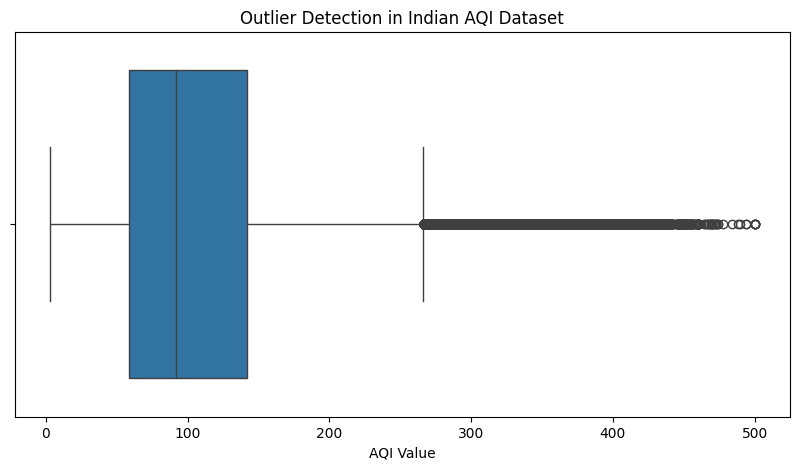

In [ ]:
# Step 11: AQI boxplot

plt.figure(figsize=(10, 5))

sns.boxplot(x=df["aqi_value"])

plt.title("Outlier Detection in Indian AQI Dataset")
plt.xlabel("AQI Value")

plt.show()

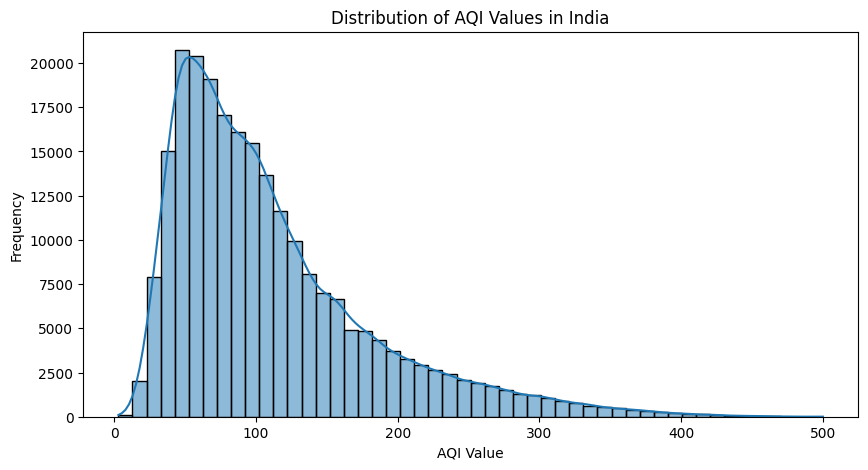

In [ ]:
# Step 12: AQI distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="aqi_value",
    bins=50,
    kde=True
)

plt.title("Distribution of AQI Values in India")
plt.xlabel("AQI Value")
plt.ylabel("Frequency")

plt.show()

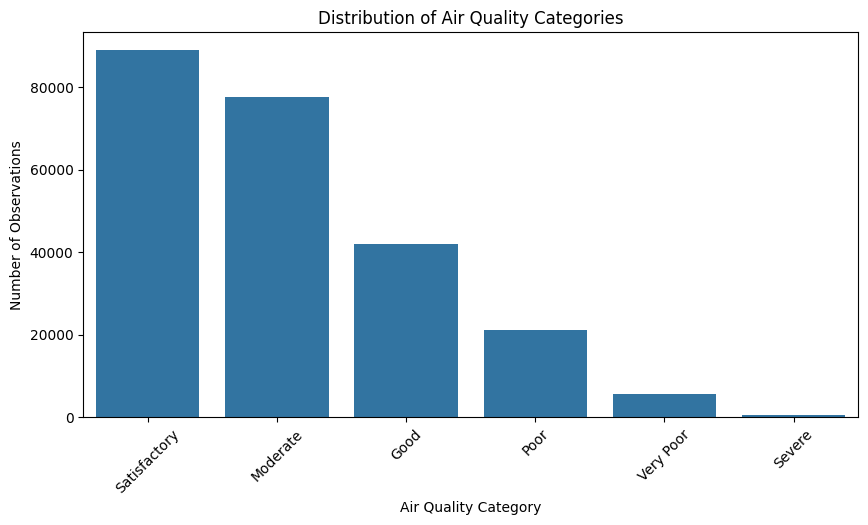

In [ ]:
# Step 13: Count air quality categories

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="air_quality_status",
    order=df["air_quality_status"].value_counts().index
)

plt.title("Distribution of Air Quality Categories")
plt.xlabel("Air Quality Category")
plt.ylabel("Number of Observations")

plt.xticks(rotation=45)

plt.show()

In [ ]:
# Step 14: Calculate average AQI for each state

state_aqi = (
    df.groupby("state")["aqi_value"]
    .mean()
    .sort_values(ascending=False)
)

print(state_aqi)

state
Delhi                          206.416889
Jharkhand                      164.940361
Himachal Pradesh               160.257036
Bihar                          157.158122
Chandigarh                     141.561778
Haryana                        140.852806
Rajasthan                      127.987248
Tripura                        126.697585
Uttar Pradesh                  126.424036
Odisha                         124.879719
Punjab                         117.854265
West Bengal                    114.192891
Assam                          114.117456
Gujarat                        110.634272
Madhya Pradesh                 108.716483
Maharashtra                    103.639833
Manipur                        100.927361
Uttarakhand                     87.898799
Telangana                       81.012444
Nagaland                        80.458725
Chhattisgarh                    78.986321
Andhra Pradesh                  77.507701
Jammu and Kashmir               69.495434
Kerala                      

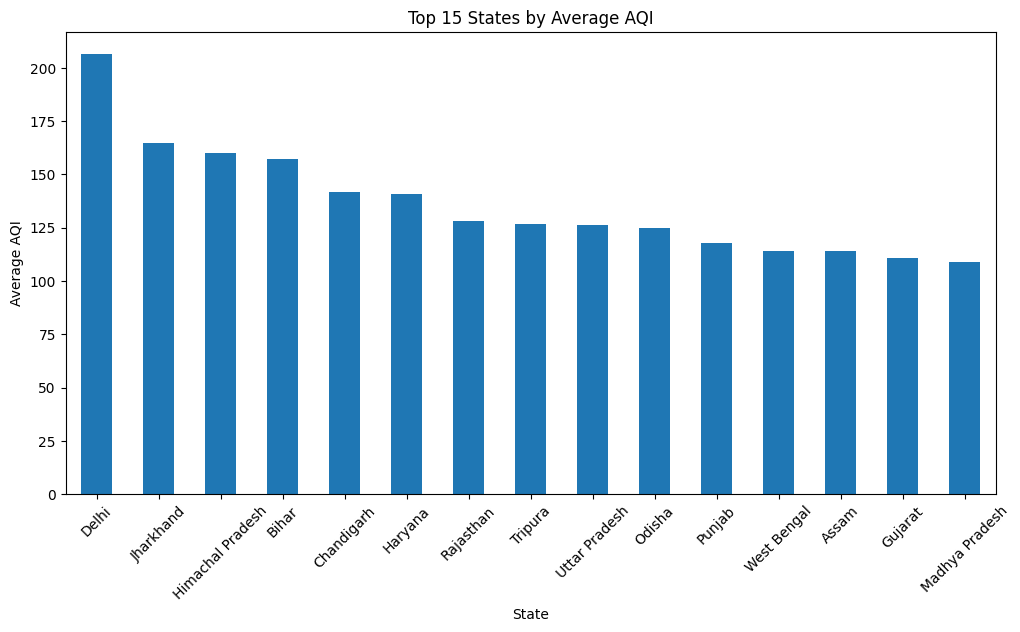

In [ ]:
plt.figure(figsize=(12, 6))

state_aqi.head(15).plot(kind="bar")

plt.title("Top 15 States by Average AQI")
plt.xlabel("State")
plt.ylabel("Average AQI")

plt.xticks(rotation=45)

plt.show()

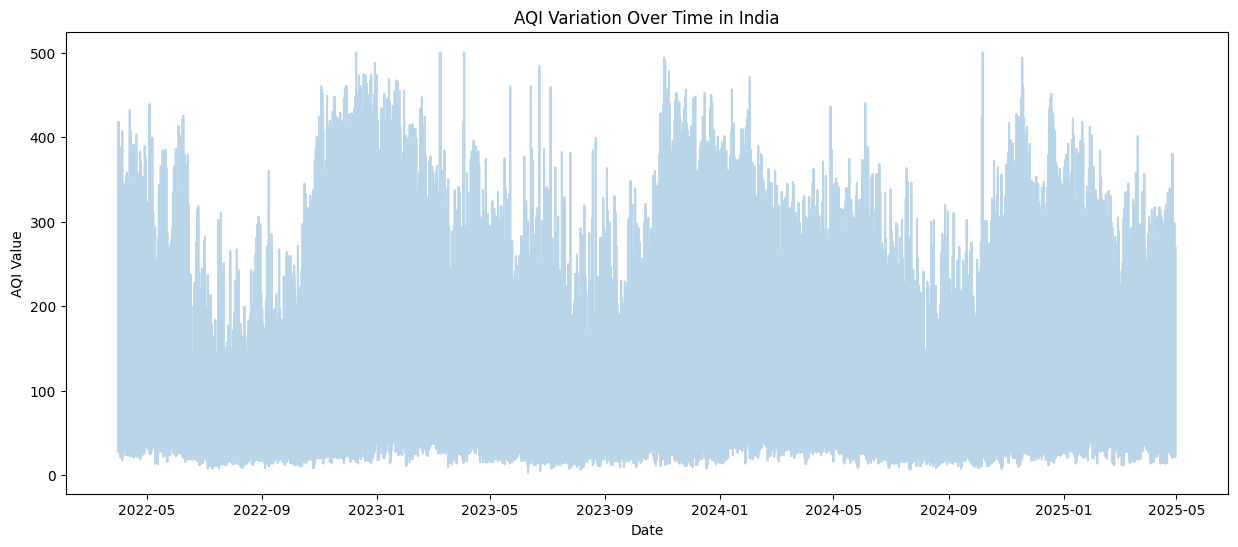

In [ ]:
# Step 15: Sort observations by date

df = df.sort_values("date")

plt.figure(figsize=(15, 6))

plt.plot(
    df["date"],
    df["aqi_value"],
    alpha=0.3
)

plt.title("AQI Variation Over Time in India")
plt.xlabel("Date")
plt.ylabel("AQI Value")

plt.show()

In [ ]:
# Step 16: Feature engineering

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["day"] = df["date"].dt.day
df["day_of_week"] = df["date"].dt.dayofweek
df["day_of_year"] = df["date"].dt.dayofyear
df["quarter"] = df["date"].dt.quarter

# Display new columns
df.head()

,date,state,area,number_of_monitoring_stations,prominent_pollutants,aqi_value,air_quality_status,unit,year,month,day,day_of_week,day_of_year,quarter
235784,2022-04-01,Odisha,Brajrajnagar,1,O3,270,Poor,number_of_monitoring_stations in Absolute Numb...,2022,4,1,4,91,2
235687,2022-04-01,Bihar,Munger,1,PM10,234,Poor,number_of_monitoring_stations in Absolute Numb...,2022,4,1,4,91,2
235686,2022-04-01,Bihar,Saharsa,1,PM10,211,Poor,number_of_monitoring_stations in Absolute Numb...,2022,4,1,4,91,2
235685,2022-04-01,Gujarat,Ankleshwar,1,PM2.5,223,Poor,number_of_monitoring_stations in Absolute Numb...,2022,4,1,4,91,2
235684,2022-04-01,Odisha,Talcher,1,PM10,37,Good,number_of_monitoring_stations in Absolute Numb...,2022,4,1,4,91,2


In [ ]:
# Step 17: Select input features

features = [
    "state",
    "area",
    "number_of_monitoring_stations",
    "prominent_pollutants",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "quarter"
]

X = df[features]

y = df["aqi_value"]

print("Input shape:", X.shape)
print("Target shape:", y.shape)

Input shape: (235785, 10)
Target shape: (235785,)


In [ ]:
# Step 18: Sort chronologically

df = df.sort_values("date").reset_index(drop=True)

X = df[features]
y = df["aqi_value"]

# 80% training, 20% testing

split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 188628
Testing records: 47157


In [ ]:
# Step 19: Identify column types

categorical_features = [
    "state",
    "area",
    "prominent_pollutants"
]

numerical_features = [
    "number_of_monitoring_stations",
    "year",
    "month",
    "day",
    "day_of_week",
    "day_of_year",
    "quarter"
]

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline

# Numerical preprocessing

numerical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

# Categorical preprocessing

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing

preprocessor = ColumnTransformer([
    ("num", numerical_transformer, numerical_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully.")

Preprocessing pipeline created successfully.


In [ ]:
!pip install xgboost

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from xgboost import XGBRegressor

from sklearn.model_selection import (
    TimeSeriesSplit,
    RandomizedSearchCV,
    GridSearchCV
)

print("All three models and tuning libraries imported.")

All three models and tuning libraries imported.


In [ ]:
# Step 21: Create tuning sample

tuning_size = min(50000, len(X_train))

X_tune = X_train.iloc[:tuning_size]
y_tune = y_train.iloc[:tuning_size]

print("Tuning sample size:", len(X_tune))

Tuning sample size: 50000


In [ ]:
# Time-series cross-validation

tscv = TimeSeriesSplit(n_splits=3)

print("Time-series validation prepared.")

Time-series validation prepared.


In [ ]:
# Step 22: Linear Regression tuning

lr_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LinearRegression())
])

lr_parameters = {
    "model__fit_intercept": [True, False]
}

lr_search = GridSearchCV(
    estimator=lr_pipeline,
    param_grid=lr_parameters,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)

lr_search.fit(X_tune, y_tune)

print("Best Linear Regression parameters:")
print(lr_search.best_params_)

print("Best CV RMSE:", -lr_search.best_score_)

Best Linear Regression parameters:
{'model__fit_intercept': False}
Best CV RMSE: 86.55553825787648


In [ ]:
# Step 23: Random Forest tuning

rf_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestRegressor(
        random_state=42,
        n_jobs=-1
    ))
])

rf_parameters = {
    "model__n_estimators": [100, 200],
    "model__max_depth": [10, 20, None],
    "model__min_samples_split": [2, 5],
    "model__min_samples_leaf": [1, 2]
}

rf_search = RandomizedSearchCV(
    estimator=rf_pipeline,
    param_distributions=rf_parameters,
    n_iter=5,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1,
    verbose=1
)

rf_search.fit(X_tune, y_tune)

print("Best Random Forest parameters:")
print(rf_search.best_params_)

print("Best CV RMSE:", -rf_search.best_score_)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best Random Forest parameters:
{'model__n_estimators': 100, 'model__min_samples_split': 5, 'model__min_samples_leaf': 1, 'model__max_depth': None}
Best CV RMSE: 68.4262705324183


In [ ]:
# Step 24: XGBoost tuning

xgb_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", XGBRegressor(
        objective="reg:squarederror",
        random_state=42,
        tree_method="hist",
        n_jobs=2
    ))
])

xgb_parameters = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [3, 5, 7],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__subsample": [0.8, 1.0],
    "model__colsample_bytree": [0.8, 1.0]
}

xgb_search = RandomizedSearchCV(
    estimator=xgb_pipeline,
    param_distributions=xgb_parameters,
    n_iter=5,
    cv=tscv,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1,
    verbose=1
)

xgb_search.fit(X_tune, y_tune)

print("Best XGBoost parameters:")
print(xgb_search.best_params_)

print("Best CV RMSE:", -xgb_search.best_score_)

Fitting 3 folds for each of 5 candidates, totalling 15 fits
Best XGBoost parameters:
{'model__subsample': 1.0, 'model__n_estimators': 300, 'model__max_depth': 5, 'model__learning_rate': 0.05, 'model__colsample_bytree': 1.0}
Best CV RMSE: 66.7501932779948


In [ ]:
# Step 25: Compare cross-validation results

tuning_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "Best CV RMSE": [
        -lr_search.best_score_,
        -rf_search.best_score_,
        -xgb_search.best_score_
    ]
})

tuning_results = tuning_results.sort_values(
    "Best CV RMSE"
)

print(tuning_results)

               Model  Best CV RMSE
2            XGBoost     66.750193
1      Random Forest     68.426271
0  Linear Regression     86.555538


In [ ]:
# Step 26: Train best models on full training data

best_lr = lr_search.best_estimator_
best_rf = rf_search.best_estimator_
best_xgb = xgb_search.best_estimator_

# Train using full training dataset

best_lr.fit(X_train, y_train)

best_rf.fit(X_train, y_train)

best_xgb.fit(X_train, y_train)

print("All tuned models trained successfully!")

All tuned models trained successfully!


In [ ]:
# Step 27: Predictions

lr_predictions = best_lr.predict(X_test)

rf_predictions = best_rf.predict(X_test)

xgb_predictions = best_xgb.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [ ]:
# Step 28: Evaluation function

def evaluate_model(model_name, y_true, y_pred):

    mae = mean_absolute_error(y_true, y_pred)

    rmse = np.sqrt(mean_squared_error(y_true, y_pred))

    r2 = r2_score(y_true, y_pred)

    return {
        "Model": model_name,
        "MAE": mae,
        "RMSE": rmse,
        "R2 Score": r2
    }

In [ ]:
# Step 29: Compare model performance

results = []

results.append(
    evaluate_model("Linear Regression", y_test, lr_predictions)
)

results.append(
    evaluate_model("Random Forest", y_test, rf_predictions)
)

results.append(
    evaluate_model("XGBoost", y_test, xgb_predictions)
)

results_df = pd.DataFrame(results)

print(results_df)

               Model        MAE       RMSE  R2 Score
0  Linear Regression  36.795765  50.303697  0.406949
1      Random Forest  38.229660  53.706025  0.324013
2            XGBoost  35.689487  47.350479  0.474538


In [ ]:
# Step 30: Select best model

best_model_name = results_df.loc[
    results_df["RMSE"].idxmin(),
    "Model"
]

print("Best Model:", best_model_name)

Best Model: XGBoost


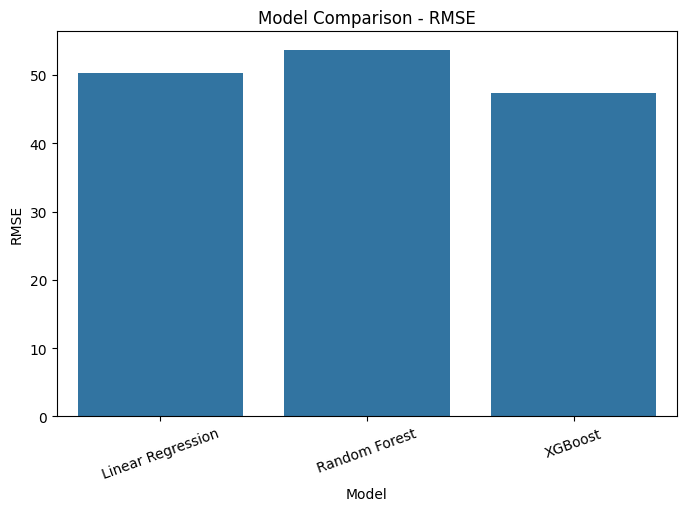

In [ ]:
# Compare RMSE

plt.figure(figsize=(8, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison - RMSE")
plt.xticks(rotation=20)

plt.show()

In [ ]:
# Step 31: Identify the best model

model_dict = {
    "Linear Regression": best_lr,
    "Random Forest": best_rf,
    "XGBoost": best_xgb
}

best_model = model_dict[best_model_name]

print("Selected model:", best_model_name)

Selected model: XGBoost


In [ ]:
# Step 32: Save the model

import joblib

joblib.dump(best_model, "best_indian_aqi_model.pkl")

print("Best model saved successfully!")


Best model saved successfully!


In [ ]:
from google.colab import files

files.download("best_indian_aqi_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
# Step 33: Save evaluation results

results_df.to_csv(
    "indian_aqi_model_comparison.csv",
    index=False
)

print("Model comparison results saved!")

Model comparison results saved!


In [ ]:
files.download("indian_aqi_model_comparison.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

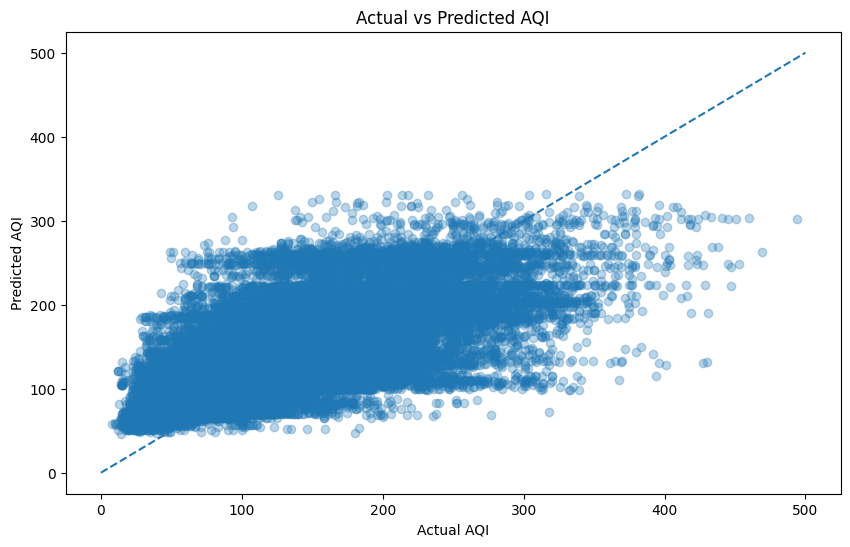

In [ ]:
# Step 34: Actual vs predicted AQI

plt.figure(figsize=(10, 6))

plt.scatter(
    y_test,
    best_model.predict(X_test),
    alpha=0.3
)

plt.xlabel("Actual AQI")
plt.ylabel("Predicted AQI")

plt.title("Actual vs Predicted AQI")

plt.plot(
    [0, 500],
    [0, 500],
    linestyle="--"
)

plt.show()

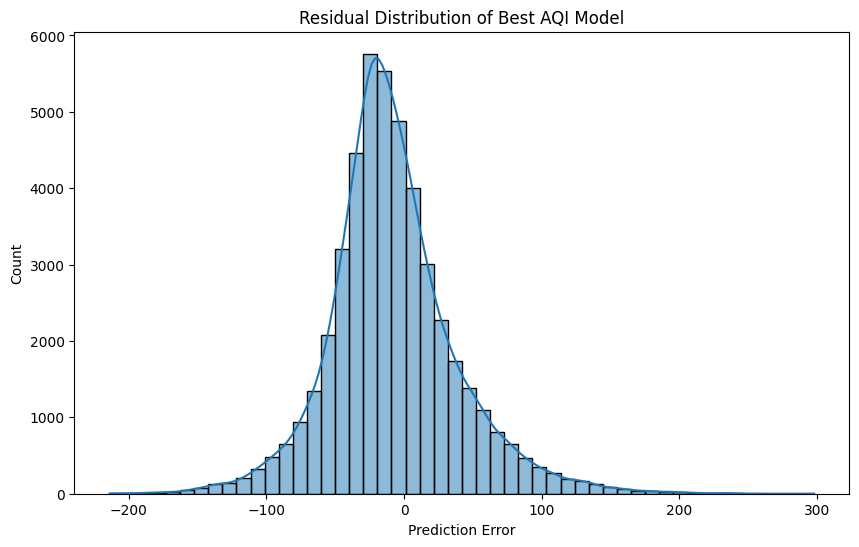

In [ ]:
# Step 35: Calculate residuals

best_predictions = best_model.predict(X_test)

residuals = y_test - best_predictions

plt.figure(figsize=(10, 6))

sns.histplot(residuals, bins=50, kde=True)

plt.title("Residual Distribution of Best AQI Model")

plt.xlabel("Prediction Error")

plt.show()

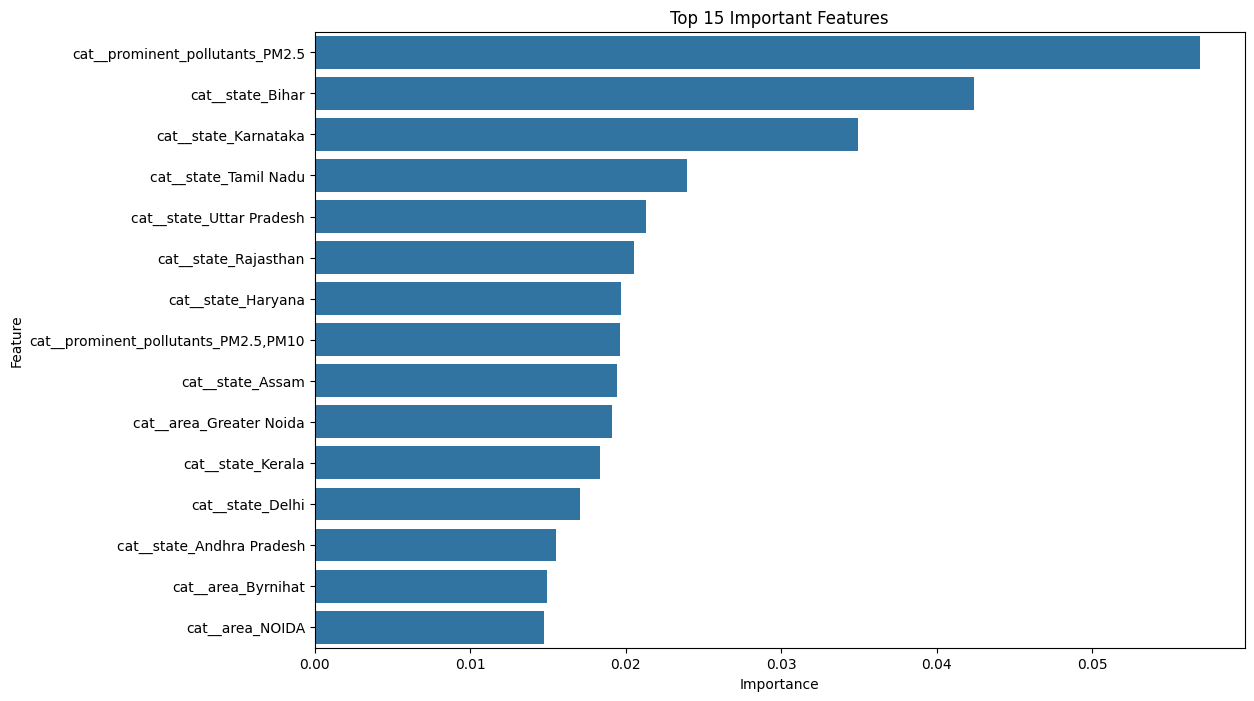

In [ ]:
# Step 36: Feature importance

if best_model_name in ["Random Forest", "XGBoost"]:

    feature_names = (
        best_model.named_steps["preprocessor"]
        .get_feature_names_out()
    )

    importance = (
        best_model.named_steps["model"]
        .feature_importances_
    )

    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    })

    importance_df = importance_df.sort_values(
        "Importance",
        ascending=False
    )

    plt.figure(figsize=(12, 8))

    sns.barplot(
        data=importance_df.head(15),
        x="Importance",
        y="Feature"
    )

    plt.title("Top 15 Important Features")

    plt.show()

else:
    print("Feature importance is not directly available for Linear Regression.")

In [ ]:
# Step 37: AQI prediction function

def predict_aqi(state, area, stations, pollutant, date):

    date = pd.to_datetime(date)

    input_data = pd.DataFrame({
        "state": [state],
        "area": [area],
        "number_of_monitoring_stations": [stations],
        "prominent_pollutants": [pollutant],
        "year": [date.year],
        "month": [date.month],
        "day": [date.day],
        "day_of_week": [date.dayofweek],
        "day_of_year": [date.dayofyear],
        "quarter": [date.quarter]
    })

    prediction = best_model.predict(input_data)

    return round(float(prediction[0]), 2)

In [ ]:
# Step 38: Get available states

print(df["state"].unique()[:20])

['Odisha' 'Maharashtra' 'Rajasthan' 'Bihar' 'Telangana' 'Haryana'
 'West Bengal' 'Karnataka' 'Punjab' 'Kerala' 'Madhya Pradesh' 'Puducherry'
 'Andhra Pradesh' 'Tamil Nadu' 'Uttar Pradesh' 'Gujarat' 'Tripura'
 'Jammu and Kashmir' 'Chandigarh' 'Assam']


In [ ]:
# Display areas for the first state

selected_state = df["state"].iloc[0]

print(
    df[df["state"] == selected_state]["area"].unique()[:20]
)

['Brajrajnagar' 'Talcher' 'Bileipada' 'Rourkela' 'Rairangpur' 'Keonjhar'
 'Nayagarh' 'Baripada' 'Suakati' 'Tensa' 'Balasore' 'Angul' 'Bhubaneswar'
 'Byasanagar' 'Cuttack' 'Barbil']


In [ ]:
# Step 39: Test AQI prediction

sample_prediction = predict_aqi(
    state=df["state"].iloc[0],
    area=df["area"].iloc[0],
    stations=int(df["number_of_monitoring_stations"].median()),
    pollutant=df["prominent_pollutants"].iloc[0],
    date="2025-05-01"
)

print("Predicted AQI:", sample_prediction)

Predicted AQI: 103.73


In [ ]:
# Step 40: Save model information

model_package = {
    "model": best_model,
    "model_name": best_model_name,
    "features": features
}

joblib.dump(
    model_package,
    "indian_aqi_prediction_package.pkl"
)

print("Model package saved successfully!")

Model package saved successfully!


In [ ]:
files.download("indian_aqi_prediction_package.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import xgboost

print("XGBoost version:", xgboost.__version__)

XGBoost version: 3.4.1


In [ ]:
import joblib

joblib.dump(
    model_package,
    "indian_aqi_prediction_package.pkl"
)

['indian_aqi_prediction_package.pkl']

In [ ]:
print(type(best_model))

print(best_model.named_steps)

<class 'sklearn.pipeline.Pipeline'>
{'preprocessor': ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median'))]),
                                 ['number_of_monitoring_stations', 'year',
                                  'month', 'day', 'day_of_week', 'day_of_year',
                                  'quarter']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['state', 'area', 'prominent_pollutants'])]), 'model': XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
  

In [ ]:
import joblib

# Save preprocessing separately
joblib.dump(
    best_model.named_steps["preprocessor"],
    "aqi_preprocessor.pkl"
)

# Save XGBoost in native JSON format
best_model.named_steps["model"].save_model(
    "aqi_xgboost_model.json"
)

print("Both files saved successfully!")

Both files saved successfully!
